# Exploring a dataset

Exploring a dataset means asking it questions before asking a model to learn from it: what one row is, what is to be predicted, what each column looks like, what is missing or strange, how the columns relate to the target and to each other. Each question has a summary or a plot that answers it, and each answer may become a decision about how to prepare the data. Exploring ends with a written list of those decisions, not with a collection of plots.

## The questions to ask

| Question | What answers it |
| --- | --- |
| What is one row, and where do the data come from? | The documentation; `shape` and the first rows |
| What kind is each column? | Types, distinct values ([Kinds of features](kinds_of_features.ipynb)) |
| What is missing, duplicated or impossible? | `isna`, `duplicated`, the minimum and maximum of each column |
| How is the target distributed? | Counts of each class, or a histogram |
| How is each feature distributed? | `describe`, histograms |
| How does each feature relate to the target? | The feature's distribution in each class, or a scatter plot against the target |
| How do the features relate to each other? | Scatter plots of pairs, correlations ([Correlation and what it misses](correlation.ipynb)) |

The first three questions check the data. The others look for patterns, and the patterns found will shape the model.

## Before the split, or after

The two groups of questions are treated differently. Checking the data (its types, what is missing, duplicated or impossible) learns nothing that a model will use, so it can look at every row; it is usually done once, when the table is built ([Where data preparation ends](../where_preparation_ends.ipynb)).

Looking for patterns is different. Which features seem to predict the target, which transformation a feature needs, where its extreme values begin: each answer becomes a choice in the model. If those choices are made looking at every row, the rows kept for the final test have helped make them, and the test no longer measures how the model does on data it hasn't seen. This is called **data snooping**. The safe order is to check the data, split off the test set ([Overfitting and the train/test split](../../supervised-learning/ml-fundamentals/overfitting_and_the_split.ipynb)), and explore patterns on the training rows only. That is the order of this notebook.

## The data: penguins of the Palmer Archipelago

Between 2007 and 2009, Kristen Gorman and the Palmer Station research programme measured penguins of three species on three islands of the Palmer Archipelago, in Antarctica. Allison Horst, Alison Hill and Kristen Gorman published the data in 2020 as an alternative to the classic iris flowers. seaborn, a plotting library, downloads a copy the first time:

In [ ]:
import seaborn as sns

penguins = sns.load_dataset("penguins", data_home="data")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [ ]:
penguins.shape

(344, 7)

Each row is one penguin: its species, the island where it was measured, the length and depth of its bill and the length of its flipper in millimetres, its body mass in grams, and its sex. The task here is to tell the species from the other columns: a classification with three classes.

## Checking the data

In [ ]:
import pandas as pd

pd.DataFrame({
    "type": penguins.dtypes.astype(str),
    "distinct values": penguins.nunique(),
    "missing": penguins.isna().sum(),
})

,type,distinct values,missing
species,str,3,0
island,str,3,0
bill_length_mm,float64,164,2
bill_depth_mm,float64,80,2
flipper_length_mm,float64,55,2
body_mass_g,float64,94,2
sex,str,2,11


Two penguins have no measurement at all, and more have no sex. The rows with a missing value, all of them:

In [ ]:
penguins[penguins.isna().any(axis=1)]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


Eleven rows: two with nothing measured, nine with every measurement but the sex. They need different decisions. A row with no measurement has nothing to learn from, and removing such rows is a fixed rule, decided without looking at any other row, so it can be done now, before the split. The missing sex of the other nine will be filled or flagged, a decision that does depend on the data ([Missing values](../missing_values.ipynb)).

Duplicated rows, and the range of each measurement:

In [ ]:
penguins.duplicated().sum()

np.int64(0)

In [ ]:
penguins.describe().loc[["min", "max"]]

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
min,32.1,13.1,172.0,2700.0
max,59.6,21.5,231.0,6300.0


No duplicates, and no impossible values: bills between 32 and 60 mm, flippers between 172 and 231 mm, masses between 2.7 and 6.3 kg are all plausible for these species. Had there been a mass of 0 or a negative length, it would have been an error to fix by a rule now; values that are only unusual are a question for [Outliers and capped values](outliers.ipynb).

The checks are done. Removing the two empty rows and splitting off a test set of 20%, keeping the proportion of each species the same on both sides:

In [ ]:
from sklearn.model_selection import train_test_split

measurements = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
penguins = penguins.dropna(subset=measurements, how="all")
train, test = train_test_split(penguins, test_size=0.2, stratify=penguins["species"], random_state=42)
len(train), len(test)

(273, 69)

From here on, only `train` is explored.

## The target

In [ ]:
train["species"].value_counts()

species
Adelie       121
Gentoo        98
Chinstrap     54
Name: count, dtype: int64

Adélie penguins are about 44% of the training rows, Gentoo 36% and Chinstrap 20%. The classes are not balanced, but not so unbalanced that a model could do well by ignoring the smallest one; still, an evaluation should look at each species, not only at the overall accuracy ([Evaluating a classifier](../../supervised-learning/evaluation/classification_metrics.ipynb)).

## Each feature, by class

A histogram of each measurement, with the three species in different colours, shows at once how each feature is distributed and how well it separates the classes:

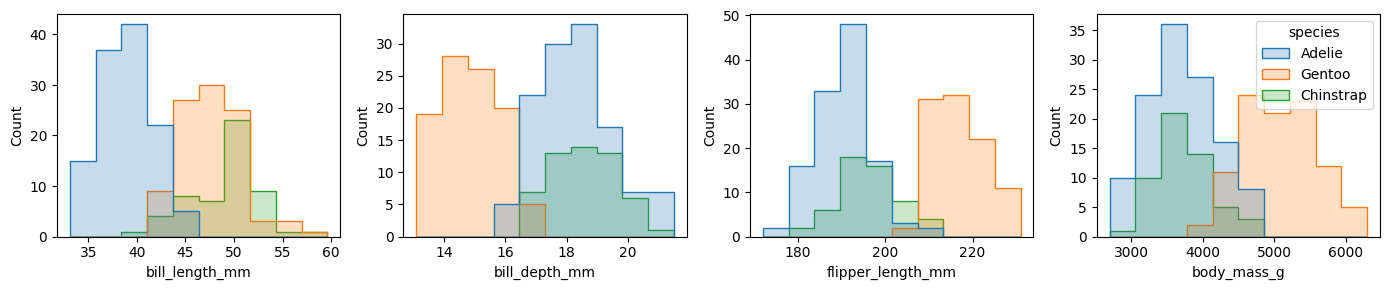

In [ ]:
import matplotlib.pyplot as plt

figure, axes = plt.subplots(1, 4, figsize=(14, 3))
for axis, measurement in zip(axes, measurements):
    sns.histplot(train, x=measurement, hue="species", element="step", ax=axis, legend=axis is axes[-1])
figure.tight_layout()

- **Flipper length** separates Gentoo penguins from the other two almost completely; **body mass** does too, less cleanly (the species overlap between about 3,950 and 4,800 g). Neither tells Adélie from Chinstrap.
- **Bill length** separates Adélie penguins, with shorter bills, from the other two.
- **Bill depth** separates Gentoo penguins, with shallower bills, from the other two.

No single measurement separates all three species, but two together could: bill length with any of the others. None of the distributions has a long tail or a cluster of extreme values; each species' measurements look roughly symmetric around their own centre.

The two categorical features, against the species:

In [ ]:
pd.crosstab(train["island"], train["species"])

species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,34,0,98
Dream,45,54,0
Torgersen,42,0,0


The island narrows the species down: Torgersen has only Adélie penguins, Chinstrap penguins were measured only on Dream and Gentoo penguins only on Biscoe, so on each of those two islands only two species are possible. A model given the island would rely on it, and it would be right to, **for these three islands**. If it is meant to recognise penguins measured somewhere else, the island would be at best useless, and at worst a shortcut that prevents the model from learning anything from the measurements. Whether a feature can be used is decided by where the model will be used, not by how much it helps on this table.

In [ ]:
train.groupby(["species", "sex"])["body_mass_g"].mean().unstack().round(0)

sex,Female,Male
species,,
Adelie,3368.0,4051.0
Chinstrap,3536.0,3971.0
Gentoo,4690.0,5509.0


Within each species, males are heavier than females, by about 435 g (Chinstrap) to 820 g (Gentoo). Sex is not informative about the species by itself (both sexes are in every species), but it explains part of the variation of the mass within a species, so a model can use it together with the mass.

## Pairs of features

A pair plot draws every pair of numerical features as a scatter plot, with each feature's distribution on the diagonal:

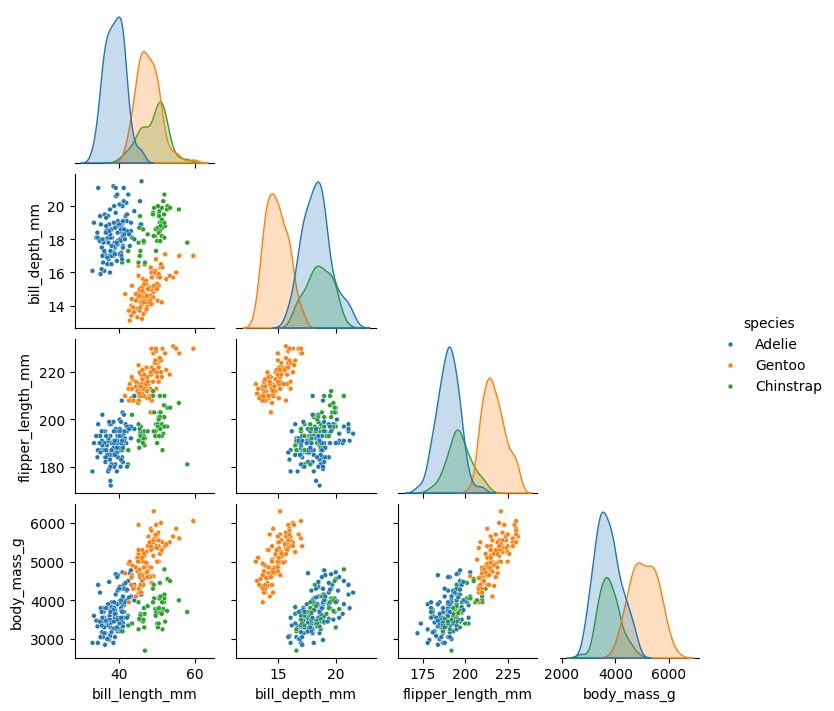

In [ ]:
sns.pairplot(train, hue="species", height=1.8, corner=True, plot_kws={"s": 12});

The scatter plots confirm what the histograms suggested. Every pair that includes bill length shows three clouds with little overlap; the pairs without it separate Gentoo penguins and leave Adélie and Chinstrap mixed. Two measurements, one of them bill length, are enough to tell the species apart, so a model for this table doesn't need to be complicated.

The plots also show features that grow together: flipper length and body mass rise along a line, so they partly carry the same information. And one pair hides a trap: bill length against bill depth slopes down for all penguins together, yet up inside each species. That pair is the subject of [Correlation and what it misses](correlation.ipynb).

## Writing the findings down

Exploring is useful only if it ends in decisions that someone can read and question later. For this table:

| Finding | Decision | Explained in |
| --- | --- | --- |
| 2 rows have no measurement | Dropped before the split, by a fixed rule | [Where data preparation ends](../where_preparation_ends.ipynb) |
| The sex of 9 penguins is missing | Filled or flagged inside the model's pipeline, fitted on the training rows | [Missing values](../missing_values.ipynb) |
| No duplicates, no impossible values | Nothing to do | |
| `island` and `sex` are categories without an order | Encoded, if used | [Encoding categories](../categorical_encoding.ipynb) |
| The island rules out one or two species | Used only if the model will see only these islands | |
| The measurements are on different scales (grams and millimetres) | Scaled for models based on distances, gradients or penalties | [Scaling numerical features](../feature_scaling.ipynb) |
| The classes are moderately unbalanced | Stratified split (done); results read per species | [Evaluating a classifier](../../supervised-learning/evaluation/classification_metrics.ipynb) |
| Flipper length and body mass grow together | Nothing for most models; matters when reading a linear model's weights | [Correlation and what it misses](correlation.ipynb) |

## Exploring larger tables

The same questions, on tables with more problems:

- [King County house sales, exploratory analysis](https://github.com/avidaldo/king-county/blob/master/01-eda.ipynb): dates, a skewed price, a category with many values, geography.
- [Thyroid disease, data preparation](https://github.com/avidaldo/thyroid/blob/master/01_data_preparation.ipynb): impossible ages, a measurement missing for almost every patient, and why that absence says something.
- [California housing, exploratory analysis](https://github.com/avidaldo/california_e2e/blob/master/workflow/02_eda.ipynb): capped values and a map.